In [100]:
#!pip install --upgrade pip
!pip install highlight_text


In [102]:

# Importa as bibliotecas necessárias
from bcb import sgs
import pandas as pd
import seaborn as sns
import matplotlib
from matplotlib import pyplot as plt
import ipeadatapy as ip
import textwrap
import highlight_text as ht


In [24]:
# Get list of available fonts
flist = matplotlib.font_manager.findSystemFonts()

# Check if 'Arial' in list of installed fonts
flist = ''.join(flist).lower()
if 'arial' in flist:
    body_font = 'Arial'
else:
    body_font = 'sans'

In [26]:
# Define background colour, text colour, and colour palette
bg_col = '#FFFFFA'
text_col = '#0D5C63'
col_palette = [
    '#E58606',
    '#5D69B1',
    '#52BCA3',
    '#99C945',
    '#CC61B0',
    '#24796C']

In [ ]:
fiscal = sgs.get({'Resultado Primário - SPC' : 4649,
'Juros Nominais - SPC' : 4616,
'Resultado Nominal - SPC' : 4583})

In [ ]:
fiscal.head()

In [ ]:
# Busca a série do índice do IPCA e renomeia a coluna de valor
ipca = (
ip.timeseries('PRECOS12_IPCA12')
[['VALUE (-)']]
.rename(columns = {'VALUE (-)' : 'ipca'})
)

In [ ]:
fiscal_ipca = fiscal.join(ipca)

In [ ]:
fiscal_ipca

In [11]:
# Calcula o deflator para deflacionar os valores
deflator = fiscal_ipca['ipca'].iloc[-1] / fiscal_ipca.loc[:,['ipca']]
# Multiplica os valores pelo deflator para obter os valores reais
fiscal_real = fiscal.mul(deflator.ipca, axis = 'index')

In [12]:
fiscal_real

,Resultado Primário - SPC,Juros Nominais - SPC,Resultado Nominal - SPC
Date,,,
2001-12-01,19802.194356,32585.797220,52387.991576
2002-01-01,-25368.247777,31606.749072,6238.501295
2002-02-01,-18077.960599,32462.002406,14384.119466
2002-03-01,-16308.983252,27388.188741,11079.205489
2002-04-01,-27187.816147,26852.421263,-335.318301
...,...,...,...
2024-08-01,21837.148715,70281.832447,92118.981161
2024-09-01,7447.937055,47112.750835,54560.687890
2024-10-01,-37219.305443,112581.109589,75361.804146


In [14]:
# Calcula os valores acumulados em 12 meses
fiscal_real_acum12 = fiscal_real.rolling(12).sum().dropna()

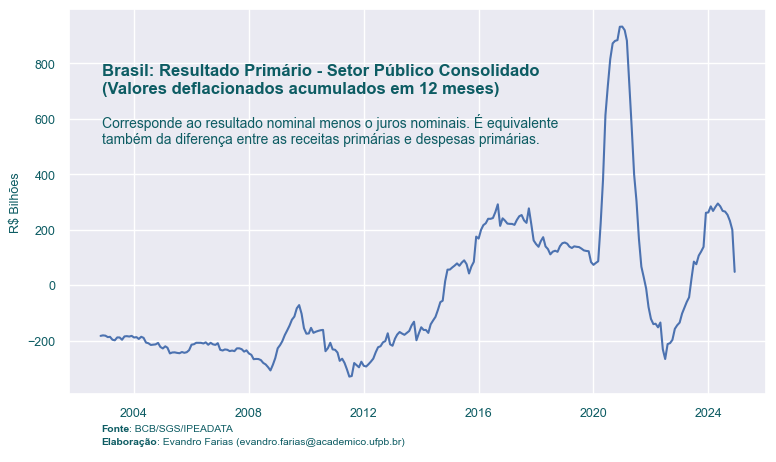

In [105]:
plt.style.use('ggplot')
sns.set_theme()
#fig = plt.figure(figsize=(8,4))
#ax = fig.add_subplot(111)
fig, ax = plt.subplots(figsize=(9,5))

# Plota
sns.lineplot(data = fiscal_real_acum12['Resultado Primário - SPC'] / 1000)
#plt.title('Resultado Primário - Setor Público Consolidado - Valores deflacionados acumulados em 12 meses', fontsize = 15)
plt.xlabel("")
plt.ylabel("R$ Bilhões",color=text_col, size=9)


title_text = ('Brasil: Resultado Primário - Setor Público Consolidado\n'
              '(Valores deflacionados acumulados em 12 meses)')
st = "Corresponde ao resultado nominal menos o juros nominais. É equivalente também da diferença entre as receitas primárias e despesas primárias."
wrapped_subtitle = '\n'.join(textwrap.wrap(st, width=70))

cap = '<Fonte::{"fontweight": "bold"}>: BCB/SGS/IPEADATA\n<Elaboração::{"fontweight": "bold"}>: Evandro Farias (evandro.farias@academico.ufpb.br)'

plt.text(12004, 800, title_text,
          #fontsize=10,
          #weight="bold",
          #color=text_col
         family=body_font,
         color=text_col,
         ha='left',
         va='top',
         size=12,
         fontweight='bold'
             ) #adicionar texto a negrito

plt.text(12004, 620, wrapped_subtitle,
          #fontsize=10,
          #weight="bold",
          #color=text_col
         family=body_font,
         color=text_col,
         ha='left',
         va='top',
         size=10,
         #fontweight='bold'
             ) #adicionar texto a negrito

plt.yticks(color=text_col, size=9)
plt.xticks(color=text_col, size=9)
# Add caption
ht.ax_text(12000, -500, cap, color=text_col,
           fontname=body_font, fontsize=7.5, vpad=0, hpad=0, vsep=3, va='top')

# Adiciona a fonte no gráfico           
# plt.annotate('Fonte: @evandro.farias com dados do BCB/SGS/IPEADATA ',
#             xy = (1.0, -0.07),
#             xycoords='axes fraction',
#             ha='right',
#             va="center",
#             fontsize=10);3
plt.savefig('resultado_primario.png')
plt.show()

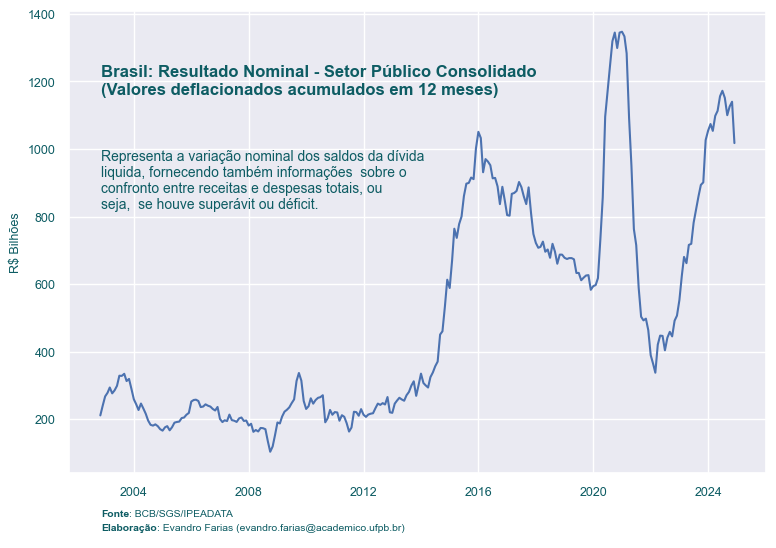

In [138]:
plt.style.use('ggplot')
sns.set_theme()
#fig = plt.figure(figsize=(8,4))
#ax = fig.add_subplot(111)
fig, ax = plt.subplots(figsize=(9,6))


# Plota
sns.lineplot(data = fiscal_real_acum12['Resultado Nominal - SPC'] / 1000)
#plt.title('Resultado Nominal - Setor Público Consolidado - Valores deflacionados acumulados em 12 meses', fontsize = 15)
plt.xlabel("")
plt.ylabel("R$ Bilhões", color=text_col, size=9)

title_text = ('Brasil: Resultado Nominal - Setor Público Consolidado\n'
              '(Valores deflacionados acumulados em 12 meses)')
st = ('''Representa a variação nominal dos saldos da dívida\n liquida, fornecendo também informações\n sobre o confronto entre receitas e despesas totais, ou seja,\n se houve superávit ou déficit.''')
wrapped_subtitle = '\n'.join(textwrap.wrap(st, width=50))

cap = '<Fonte::{"fontweight": "bold"}>: BCB/SGS/IPEADATA\n<Elaboração::{"fontweight": "bold"}>: Evandro Farias (evandro.farias@academico.ufpb.br)'

plt.text(12004, 1250, title_text,
          #fontsize=10,
          #weight="bold",
          #color=text_col
         family=body_font,
         color=text_col,
         ha='left',
         va='top',
         size=12,
         fontweight='bold'
             ) #adicionar texto a negrito

plt.text(12004, 1000, wrapped_subtitle,
          #fontsize=10,
          #weight="bold",
          #color=text_col
         family=body_font,
         color=text_col,
         ha='left',
         va='top',
         size=10,
         #fontweight='bold'
             ) #adicionar texto a negrito

plt.yticks(color=text_col, size=9)
plt.xticks(color=text_col, size=9)
# Add caption
ht.ax_text(12000, -68, cap, color=text_col,
           fontname=body_font, fontsize=7.5, vpad=0, hpad=0, vsep=3, va='top')

plt.savefig('resultado_nominal.png')

plt.show()


# Adiciona a fonte no gráfico           
# plt.annotate('Fonte: @evandro.farias com dados do BCB/SGS/IPEADATA ',
#             xy = (1.0, -0.07),
#             xycoords='axes fraction',
#             ha='right',
#             va="center",
#             fontsize=10);

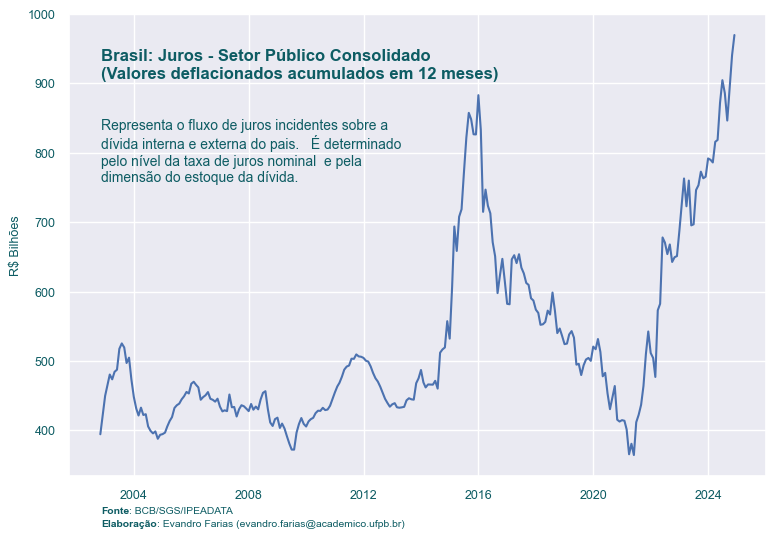

In [147]:
plt.style.use('ggplot')
sns.set_theme()
#fig = plt.figure(figsize=(8,4))
#ax = fig.add_subplot(111)
fig, ax = plt.subplots(figsize=(9,6))

# Plota
sns.lineplot(data = fiscal_real_acum12['Juros Nominais - SPC'] / 1000)
#plt.title('Juros Nominais - Setor Público Consolidado - Valores deflacionados acumulados em 12 meses', fontsize = 15)
plt.xlabel("")
plt.ylabel("R$ Bilhões", color=text_col, size=9)

title_text = ('Brasil: Juros - Setor Público Consolidado\n'
              '(Valores deflacionados acumulados em 12 meses)')
st = ('''Representa o fluxo de juros incidentes sobre a dívida interna e externa do pais.\n
 É determinado pelo nível da taxa de juros nominal\n e pela dimensão do estoque da dívida.''')

wrapped_subtitle = '\n'.join(textwrap.wrap(st, width=50))

cap = '<Fonte::{"fontweight": "bold"}>: BCB/SGS/IPEADATA\n<Elaboração::{"fontweight": "bold"}>: Evandro Farias (evandro.farias@academico.ufpb.br)'

plt.text(12004, 950, title_text,
          #fontsize=10,
          #weight="bold",
          #color=text_col
         family=body_font,
         color=text_col,
         ha='left',
         va='top',
         size=12,
         fontweight='bold'
             ) #adicionar texto a negrito

plt.text(12004, 850, wrapped_subtitle,
          #fontsize=10,
          #weight="bold",
          #color=text_col
         family=body_font,
         color=text_col,
         ha='left',
         va='top',
         size=10,
         #fontweight='bold'
             ) #adicionar texto a negrito

plt.yticks(color=text_col, size=9)
plt.xticks(color=text_col, size=9)
# Add caption
ht.ax_text(12000, 290, cap, color=text_col,
           fontname=body_font, fontsize=7.5, vpad=0, hpad=0, vsep=3, va='top')

plt.savefig('juros_nominal.png')

plt.show()
# Adiciona a fonte no gráfico           
# plt.annotate('Fonte: @evandro.farias com dados do BCB/SGS/IPEADATA ',
#             xy = (1.0, -0.07),
#             xycoords='axes fraction',
#             ha='right',
#             va="center",
#             fontsize=10);